

---

## **Problem Statement**

In many real-world scenarios, users seek contextual information about the current date and time as part of their natural language queries. For example:

* *“What is today’s date?”*
* *“Can you tell me the current time before I schedule a meeting?”*

While large language models (LLMs) can generate approximate or static answers, they are **not inherently aware of real-time system information**. As a result, they may provide outdated or fabricated responses when asked about the current date or time.

To ensure accuracy, an intelligent assistant must:

1. **Understand natural language queries referring to temporal context.**
2. **Automatically invoke tools that fetch real-time system date and time.**
3. **Integrate tool outputs into a conversational, human-friendly response.**

This functionality is crucial in **productivity tools, scheduling assistants, personal reminders, and business applications**, where real-time awareness significantly enhances user experience and reliability.

---

## **Objective**

Design and implement a **LangChain-powered agent** that integrates real-time utilities for date and time. The agent should:

* **Detect** when a user query involves current date or time.
* **Automatically call the appropriate tool** (`get_current_date` or `get_current_time`).
* **Leverage LangChain’s tool-calling framework** to handle reasoning and orchestration.
* **Maintain a reasoning trace** using `agent_scratchpad` for clarity.
* **Provide responses** in a conversational and context-aware format, ensuring outputs are both precise and user-friendly.

---



In [1]:
# Langchain Simple Agent

# Import required libraries

# For calling the Openai API
from langchain_openai import ChatOpenAI # LLM BRAIN - ENGINE

from langchain_core.prompts import ChatPromptTemplate, MessagesPlaceholder # MESSAGES - CHASSIS
# ChatPromptTemplate: It is used to create a prompt template for chat models. This helps in structuring the input for the model.
# MessagesPlaceholder: It is used to indicate where the messages should be placed in the prompt template. This allows for dynamic insertion of messages during the conversation.

from langchain.tools import tool # HANDS - DASHBOARD
# tool: It is used to define a tool that can be called by the agent. This allows the agent to perform specific actions or retrieve information.

from langchain.agents import create_tool_calling_agent, AgentExecutor
# create_tool_calling_agent: It is used to create an agent that can call tools. This allows the agent to use the defined tools to perform tasks.
# AgentExecutor: It is used to execute the agent. This allows the agent to process inputs

In [2]:
# Load the environment variables from the .env file
from dotenv import load_dotenv
load_dotenv()  # Load environment variables from .env file

True

In [3]:
llm = ChatOpenAI(model="gpt-4o")
# https://python.langchain.com/docs/integrations/chat/openai/

In [4]:
# Step 5: Create prompt template (IMPORTANT: include input & agent_scratchpad)

prompt = ChatPromptTemplate.from_messages([
    ("system", "You are a smart assistant. You can use tools whenever necessary to answer user questions."),
    ("user", "{input}"),
    MessagesPlaceholder(variable_name="agent_scratchpad")  # Required
    # MessagesPlaceholder - A special placeholder used by LangChain agents to store: a. Intermediate reasoning steps, b. Tool calls, c. Tool outputs - ReAct Style (Thoughts, Actions, and Observations)
])

In [11]:
from datetime import datetime

now = datetime.now()
print("Date:", now.strftime("%Y-%m-%d"))
print("Time:", now.strftime("%H:%M:%S"))

Date: 2026-10-28
Time: 12:44:52


In [12]:
# Tool Definitions

@tool
def get_current_date_in_india():
    """Get the current date in India."""
    india_time = datetime.now()  # Assuming the server is set to IST
    return f"The current date in India is: {india_time.strftime('%Y-%m-%d')}"

@tool
def get_current_time_in_india():
    """Get the current time in India."""
    india_time = datetime.now()  # Assuming the server is set to IST
    return f"The current time in India is: {india_time.strftime('%H:%M:%S')}"

tools = [get_current_date_in_india, get_current_time_in_india]

In [13]:
agent = create_tool_calling_agent(
    llm=llm,
    tools=tools,
    prompt=prompt
)

In [14]:
# Wrap the agent in an AgentExecutor
agent_executor = AgentExecutor(
    agent=agent,
    tools=tools,
    verbose=True # Set verbose=True to see the agent's reasoning and tool calls in the output
)

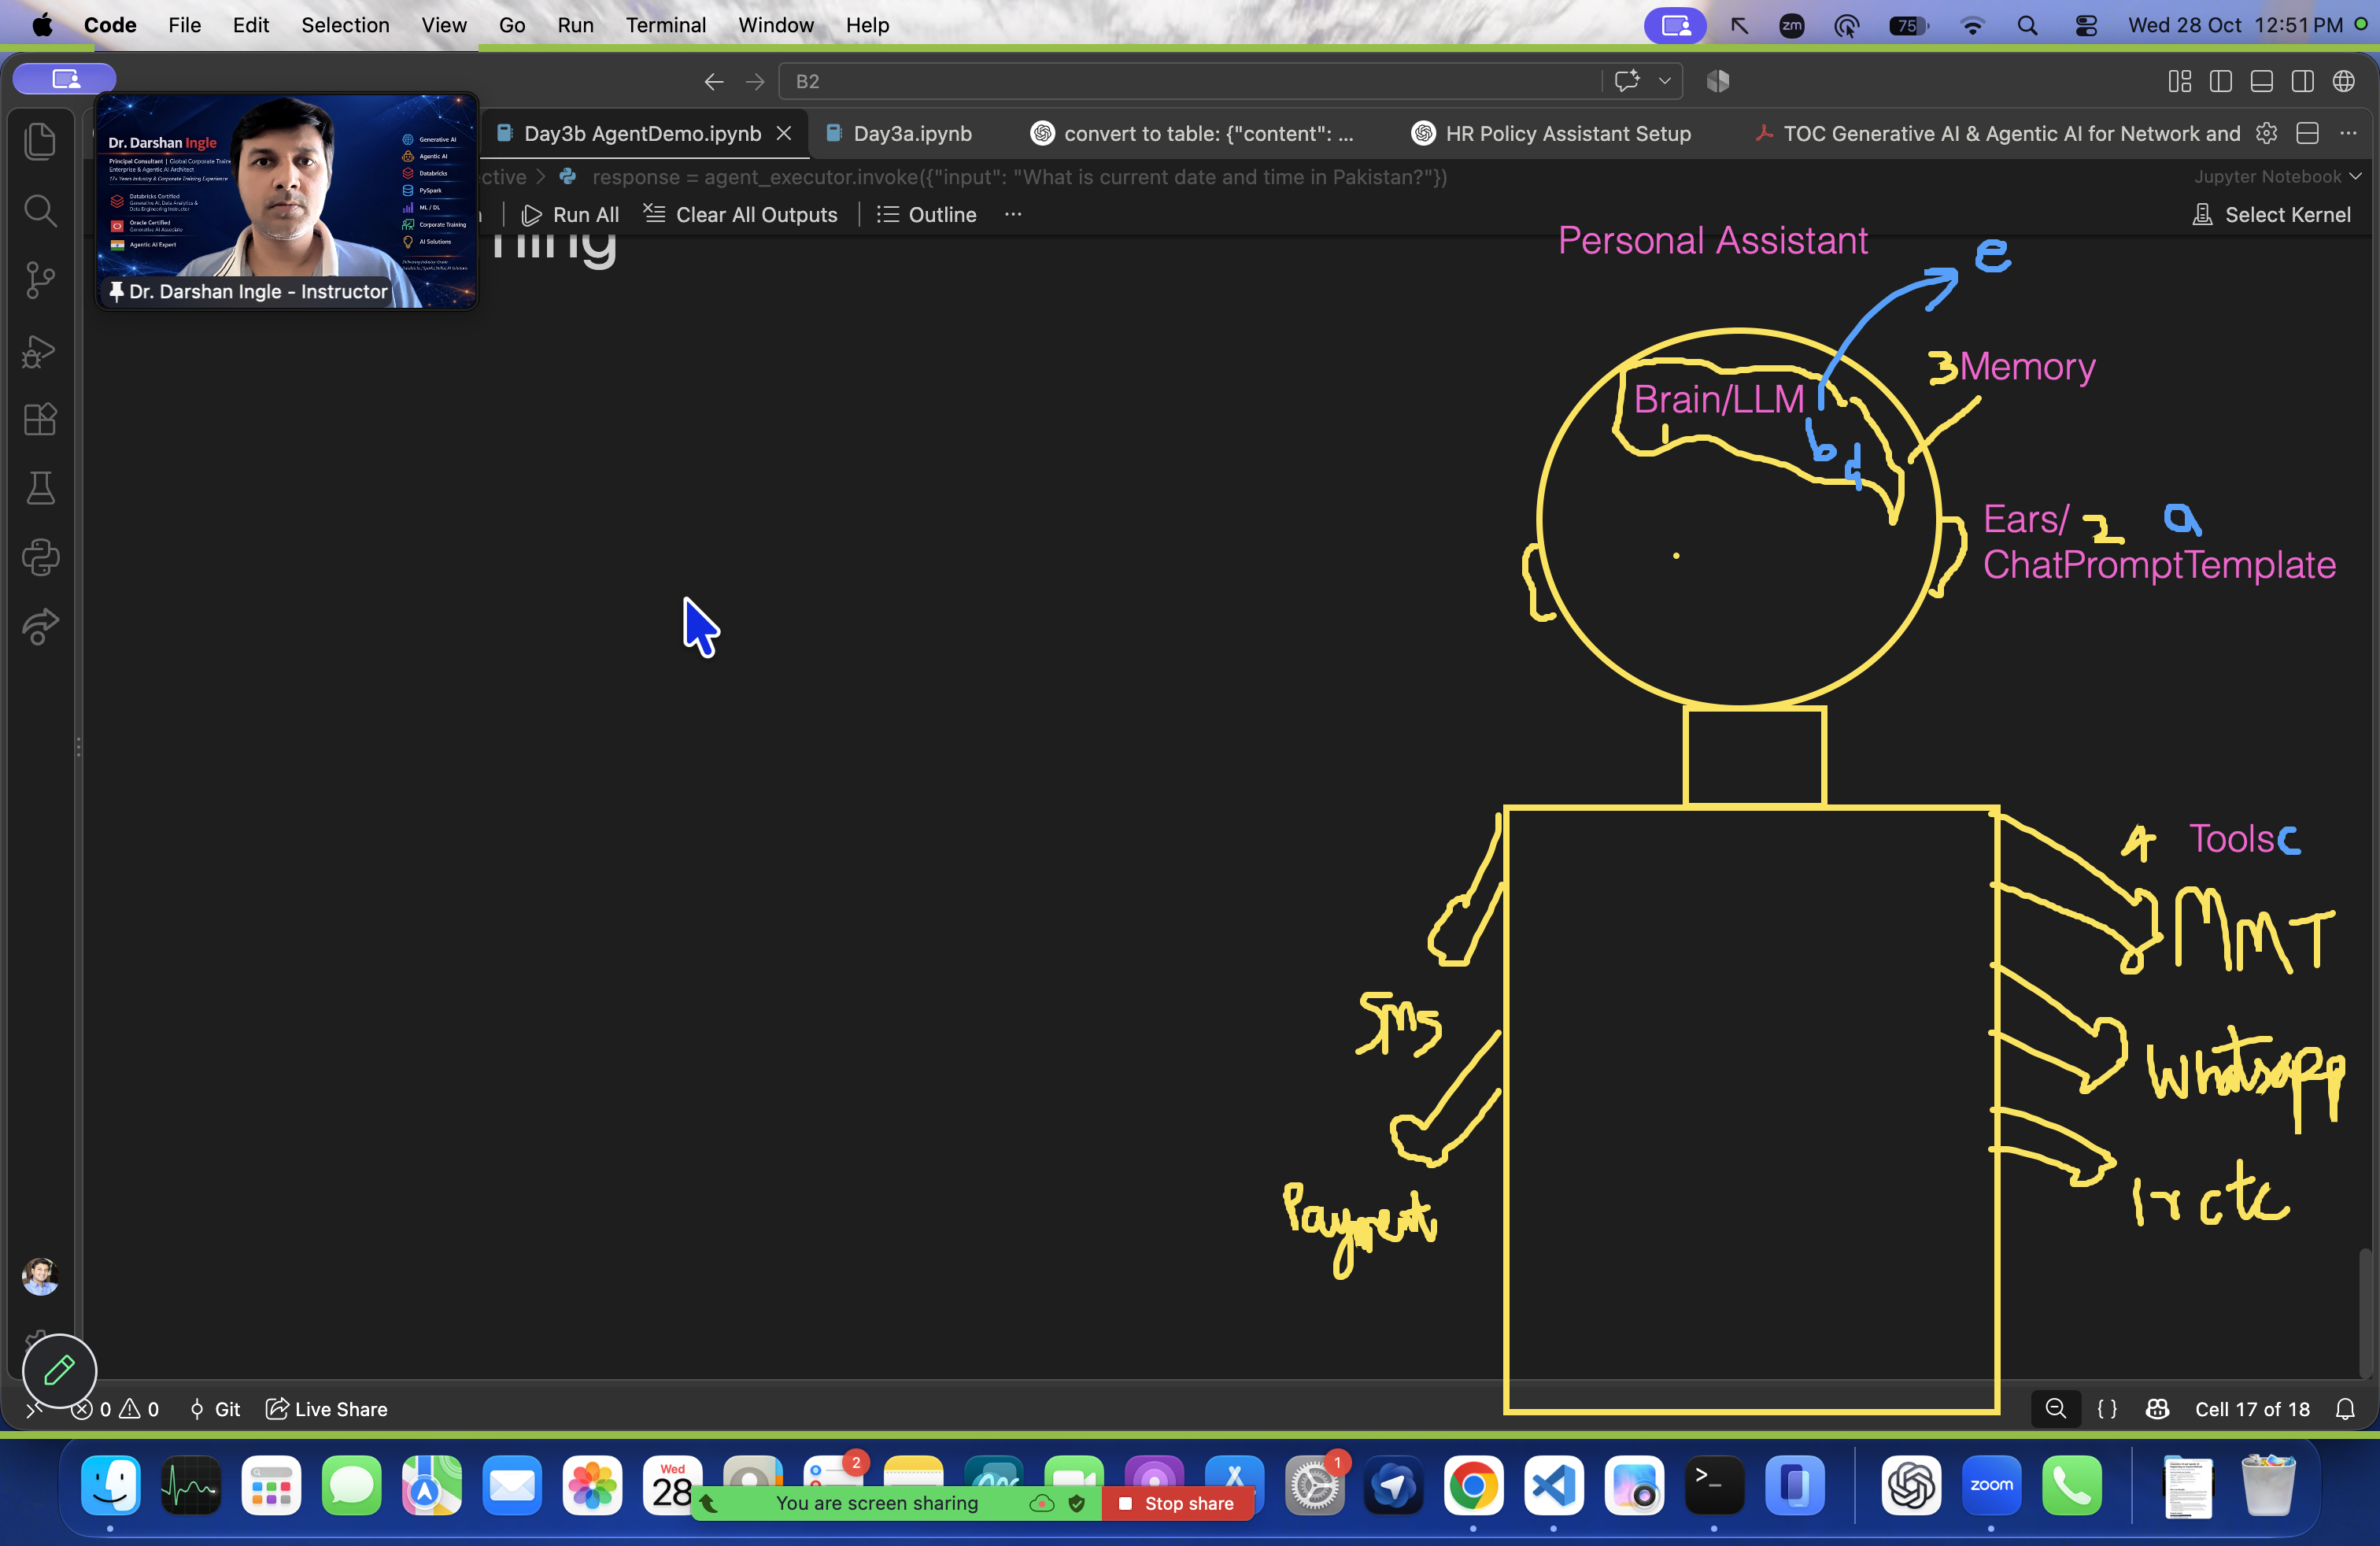

In [15]:
response = agent_executor.invoke({"input": "Explain the process of photosynthesis in 5 lines."})
print(response['output'])



> Entering new AgentExecutor chain...
Photosynthesis is the process by which green plants, algae, and some bacteria convert light energy into chemical energy. It primarily occurs in the chloroplasts of plant cells where chlorophyll absorbs sunlight. This energy is used to convert carbon dioxide from the air and water from the soil into glucose, a simple sugar that serves as food for the plant. Oxygen is released as a byproduct of this reaction. The overall reaction can be summarized as: 6CO₂ + 6H₂O + light energy → C₆H₁₂O₆ + 6O₂.

> Finished chain.
Photosynthesis is the process by which green plants, algae, and some bacteria convert light energy into chemical energy. It primarily occurs in the chloroplasts of plant cells where chlorophyll absorbs sunlight. This energy is used to convert carbon dioxide from the air and water from the soil into glucose, a simple sugar that serves as food for the plant. Oxygen is released as a byproduct of this reaction. The overall reaction can be summ

In [16]:
response = agent_executor.invoke({"input": "What is today's date in India?"})
print(response['output'])



> Entering new AgentExecutor chain...

Invoking: `get_current_date_in_india` with `{}`


The current date in India is: 2026-10-28Today's date in India is October 28, 2026.

> Finished chain.
Today's date in India is October 28, 2026.


In [17]:
response = agent_executor.invoke({"input": "What is current time in India?"})
print(response['output'])



> Entering new AgentExecutor chain...

Invoking: `get_current_time_in_india` with `{}`


The current time in India is: 12:48:25The current time in India is 12:48 PM.

> Finished chain.
The current time in India is 12:48 PM.


In [18]:
response = agent_executor.invoke({"input": "What is current date and time in India?"})
print(response['output'])



> Entering new AgentExecutor chain...

Invoking: `get_current_date_in_india` with `{}`


The current date in India is: 2026-10-28
Invoking: `get_current_time_in_india` with `{}`


The current time in India is: 12:48:39The current date in India is: October 28, 2026, and the current time is: 12:48 PM.

> Finished chain.
The current date in India is: October 28, 2026, and the current time is: 12:48 PM.


In [19]:
response = agent_executor.invoke({"input": "What is current date and time in Pakistan?"})
print(response['output'])



> Entering new AgentExecutor chain...

Invoking: `get_current_date_in_india` with `{}`


The current date in India is: 2026-10-28
Invoking: `get_current_time_in_india` with `{}`


The current time in India is: 12:48:56The current date in India is October 28, 2026, and the current time is 12:48:56 PM. 

Pakistan is approximately 30 minutes behind Indian Standard Time (IST). Therefore, the current date in Pakistan is also October 28, 2026, and the current time is 12:18:56 PM.

> Finished chain.
The current date in India is October 28, 2026, and the current time is 12:48:56 PM. 

Pakistan is approximately 30 minutes behind Indian Standard Time (IST). Therefore, the current date in Pakistan is also October 28, 2026, and the current time is 12:18:56 PM.


# Happy Learning